<a href="https://colab.research.google.com/github/jasonenkristo123/AIML-Learn/blob/main/Learn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
import pandas as pd
import numpy as np

drive.mount('/content/drive', force_remount=True)
csv_path = '/content/drive/MyDrive/datapractice/telco.csv'

Mounted at /content/drive


In [3]:
df = pd.read_csv(csv_path, on_bad_lines='skip', skip_blank_lines=True)

print("Data Info")
df.info()

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)
df['Tenure_Years'] = (df['tenure'] / 12).round(1)

avg_charges_by_contract = df.groupby('Contract')['MonthlyCharges'].mean().reset_index()

print("total tagihan per contract")
print(avg_charges_by_contract)
print(df[['tenure', 'Tenure_Years', 'TotalCharges']].head())

Data Info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null 

0        No
1        No
2       Yes
3        No
4       Yes
       ... 
7038     No
7039     No
7040     No
7041    Yes
7042     No
Name: Churn, Length: 7043, dtype: object


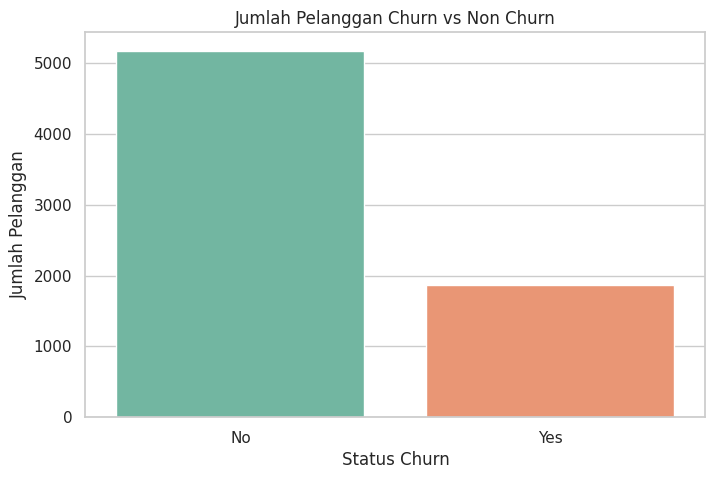

Cek Tagihan


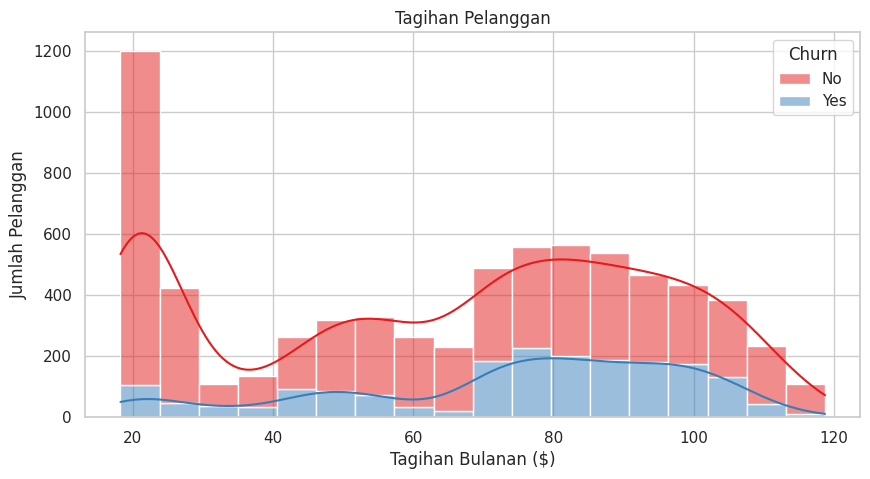

Cek kontrak apa yang kabur


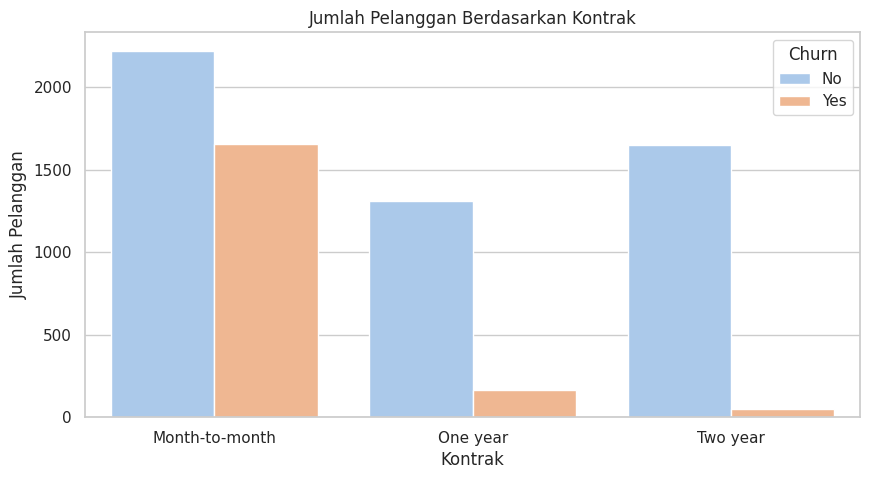

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print(df['Churn'])
plt.figure(figsize=(8, 5))
plt.title("Jumlah Pelanggan Churn vs Non Churn")
sns.countplot(data=df, x='Churn', palette="Set2", hue="Churn")
plt.xlabel("Status Churn")
plt.ylabel("Jumlah Pelanggan")
plt.show()


print("Cek Tagihan")
plt.figure(figsize=(10, 5))
plt.title("Tagihan Pelanggan")
sns.histplot(data=df, x="MonthlyCharges", hue='Churn', kde=True, palette="Set1", multiple="stack")
plt.xlabel("Tagihan Bulanan ($)")
plt.ylabel("Jumlah Pelanggan")
plt.show()

print("Cek kontrak apa yang kabur")
plt.figure(figsize=(10, 5))
plt.title("Jumlah Pelanggan Berdasarkan Kontrak")
sns.countplot(data=df, x='Contract', hue='Churn', palette="pastel")
plt.xlabel("Kontrak")
plt.ylabel("Jumlah Pelanggan")
plt.show()

In [54]:
if 'customerID' in df.columns:
    df.drop(columns=['customerID'], inplace=True)

df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
contract_map = {
    'Month-to-month': 0,
    'One year': 1,
    'Two year': 2
}
df['Contract'] = df['Contract'].map(contract_map)
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Tenure_Years
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,No,NaN,Yes,Electronic check,29.85,29.85,NaN,0.1
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,No,No,NaN,No,Mailed check,56.95,1889.50,NaN,2.8
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,No,NaN,Yes,Mailed check,53.85,108.15,NaN,0.2
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,Yes,No,No,NaN,No,Bank transfer (automatic),42.30,1840.75,NaN,3.8
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,No,NaN,Yes,Electronic check,70.70,151.65,NaN,0.2
